# 🔭 Lesson 13 · Transformers & Attention

*“Attention is all you need”: a 2017 title that turned out to be a prophecy.*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~140 min | 🔴 Advanced | Day 11–12 | Lessons 05, 11 (shapes, sequence models) |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Explain **why** attention was invented and what **query / key / value** mean
- Compute **scaled dot-product attention** by hand and implement it (with **masks**) from scratch
- Build **multi-head self-attention** and a full **Transformer encoder block** (residuals + LayerNorm + feed-forward)
- Understand **positional encodings** and show that attention alone ignores word/patch order
- Distinguish **encoder-only, decoder-only and encoder-decoder** models (BERT / GPT / T5 / ViT)
- Train a **mini Vision Transformer** on MNIST and **visualise its attention**
- Weigh Transformers against CNNs and RNNs honestly (data hunger, O(n²) cost)

## 🗺 Roadmap
1. Why attention?
2. Attention by hand
3. Why divide by √d?
4. Multi-head self-attention
5. Order blindness & positional encoding
6. The encoder block
7. Masks & the three families
8. Mini Vision Transformer
9. Looking at attention
10. Trade-offs
11. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import math, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
cpu = torch.device('cpu')
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 💡 1. Why attention?

RNNs (Lesson 11) read a sequence **one step at a time**, squeezing everything seen so far into one hidden vector. Two weaknesses:

1. **Information bottleneck:** to use a fact from step 3 at step 300, it must survive 297 updates of a fixed-size memory.
2. **No parallelism:** step *t* needs step *t−1*, so you can't use a GPU's thousands of cores across time.

**Attention** removes both. Instead of a single running summary, *every position can look directly at every other position* and decide how much to **listen** to each: all positions at once, in parallel.

> 🌽 **Analogy: a village meeting.** Before deciding what to say, each person asks a *question* ("who here knows about rainfall?"). Every person holds up a *label* describing what they know (their *key*) and has some actual *information* to share (their *value*). Each speaker compares their question with everyone's labels, gives more attention to the best matches, and blends those people's information. That is **attention**:
>
> **Query** (what I'm looking for) · **Key** (what I offer: used for matching) · **Value** (what I actually contribute).

$$\boxed{\ \text{Attention}(Q,K,V)=\operatorname{softmax}\!\Big(\frac{QK^{\top}}{\sqrt{d_k}}\Big)V\ }$$

Read it left to right: *compare* every query with every key (`QKᵀ`), *normalise* to weights that sum to 1 (`softmax`), then *take a weighted average of the values*.

---
## 🧮 2. Attention by hand

Three tokens with 2-D vectors; to keep the arithmetic visible we use $Q=K=V=X$:

$$X=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix},\qquad QK^\top=\begin{bmatrix}1&0&1\\0&1&1\\1&1&2\end{bmatrix},\qquad \frac{QK^\top}{\sqrt2}\approx\begin{bmatrix}.71&0&.71\\0&.71&.71\\.71&.71&1.41\end{bmatrix}$$

**Row 1** (token 1's question): scores $(.71,\,0,\,.71)$ → softmax $\approx(.40,\,.20,\,.40)$. Token 1 pays 40 % attention to itself, 20 % to token 2, 40 % to token 3. Its new representation is
$.40\,(1,0)+.20\,(0,1)+.40\,(1,1)=(.80,\,.60)$: a **blend** of the tokens it attended to. Let's verify in code (and write a reusable function):

attention weights (rows sum to 1):
 [[0.4  0.2  0.4 ]
 [0.2  0.4  0.4 ]
 [0.25 0.25 0.5 ]]
outputs:
 [[0.8  0.6 ]
 [0.6  0.8 ]
 [0.75 0.75]]


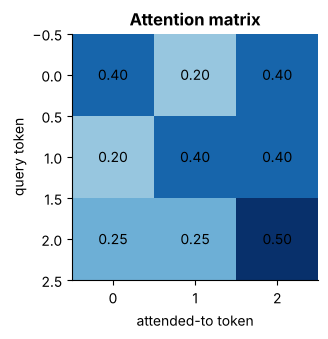

In [2]:
def softmax(z, axis=-1):
    e = np.exp(z - z.max(axis=axis, keepdims=True))
    return e / e.sum(axis=axis, keepdims=True)

def attention(Q, K, V, mask=None):
    """Scaled dot-product attention. mask: boolean (n_q, n_k), True = allowed to attend."""
    scores = Q @ K.T / np.sqrt(K.shape[-1])
    if mask is not None:
        scores = np.where(mask, scores, -1e9)             # forbidden positions get ~zero weight after softmax
    weights = softmax(scores)
    return weights @ V, weights

X = np.array([[1., 0.], [0., 1.], [1., 1.]])
out, w = attention(X, X, X)
print("attention weights (rows sum to 1):\n", w.round(2))
print("outputs:\n", out.round(2))
fig, ax = plt.subplots(figsize=(3.6, 3.2)); im = ax.imshow(w, cmap="Blues", vmin=0); ax.set(xlabel="attended-to token", ylabel="query token", title="Attention matrix"); ax.grid(False)
for i in range(3):
    for j in range(3): ax.text(j, i, f"{w[i, j]:.2f}", ha="center", va="center")
plt.show()

> 💡 **Big idea**: The output for each token is a **data-dependent weighted average** of all tokens. Convolutions mix a *fixed local neighbourhood* with *fixed weights*; attention mixes *everyone* with weights *computed from the content*. That flexibility is its power, and its cost.

---
## 📏 3. Why divide by √d?

If query and key entries have unit variance, the dot product of two $d$-dimensional vectors has variance $d$: its typical size grows like $\sqrt d$. Large scores push softmax into saturation (nearly one-hot), where **gradients vanish** (the same story as sigmoid in Lesson 02). Dividing by $\sqrt{d}$ restores unit variance.

In [3]:
rng = np.random.default_rng(0)
for d in [4, 64, 512]:
    q, K = rng.normal(size=d), rng.normal(size=(10, d))
    raw = K @ q; scaled = raw / np.sqrt(d)
    print(f"d={d:3d}: std of raw scores {raw.std():6.2f} → biggest attention weight {softmax(raw).max():.2f}   |   scaled: std {scaled.std():4.2f} → biggest weight {softmax(scaled).max():.2f}")

d=  4: std of raw scores   0.63 → biggest attention weight 0.20   |   scaled: std 0.31 → biggest weight 0.15
d= 64: std of raw scores   6.42 → biggest attention weight 0.95   |   scaled: std 0.80 → biggest weight 0.25
d=512: std of raw scores  22.56 → biggest attention weight 0.75   |   scaled: std 1.00 → biggest weight 0.19


---
## 🧩 4. Multi-head self-attention

In **self-attention** the queries, keys and values all come from the *same* sequence, via three learned linear maps: $Q=XW_Q,\ K=XW_K,\ V=XW_V$. The model *learns* what to ask, offer and say.

A single attention pattern is limiting (one head can't track "who is the subject?" and "which number goes with which unit?" at once). **Multi-head attention** runs $h$ attention operations in parallel, each in a lower-dimensional subspace ($d_k=d/h$), then concatenates and mixes them with $W_O$.

```
x (B,T,d) ──▶ Linear → Q,K,V ──▶ split into h heads: (B,h,T,d/h) ──▶ attention per head ──▶ concat → (B,T,d) ──▶ Linear W_O
```

In [4]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        assert d % heads == 0, "d must be divisible by the number of heads"
        self.h, self.dk = heads, d // heads
        self.qkv = nn.Linear(d, 3 * d)                        # one matrix produces Q, K and V
        self.out = nn.Linear(d, d)                            # W_O
    def forward(self, x, mask=None):                          # x: (B, T, d)
        B, T, d = x.shape
        q, k, v = self.qkv(x).reshape(B, T, 3, self.h, self.dk).permute(2, 0, 3, 1, 4)   # each (B, h, T, dk)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.dk)                           # (B, h, T, T)
        if mask is not None:
            scores = scores.masked_fill(~mask, float("-inf"))
        attn = scores.softmax(-1)
        self.last_attn = attn.detach()                         # keep for visualisation
        out = (attn @ v).transpose(1, 2).reshape(B, T, d)      # merge heads back
        return self.out(out)

mha = MultiHeadSelfAttention(d=16, heads=4)
x = torch.randn(2, 5, 16)
print("input", tuple(x.shape), "→ output", tuple(mha(x).shape), "| attention weights", tuple(mha.last_attn.shape), "= (batch, heads, query, key)")

input (2, 5, 16) → output (2, 5, 16) | attention weights (2, 4, 5, 5) = (batch, heads, query, key)


---
## 🔀 5. Attention is blind to order: positional encodings

Attention treats its input as a **set**: shuffle the tokens and you simply get the outputs shuffled the same way (*permutation equivariance*). "Dog bites man" and "man bites dog" would look identical! Let's prove it:

In [5]:
torch.manual_seed(0)
mha = MultiHeadSelfAttention(16, 4).eval()
x = torch.randn(1, 6, 16); perm = torch.randperm(6)
with torch.no_grad():
    out, out_perm = mha(x), mha(x[:, perm])
print("shuffling the input just shuffles the output:", torch.allclose(out[:, perm], out_perm, atol=1e-6))

shuffling the input just shuffles the output: True


The fix: **add position information** to each token's embedding before attention. Two common choices: **learned** position vectors (what ViT uses) or the original **sinusoidal** encoding:

$$PE_{(pos,2i)}=\sin\!\Big(\frac{pos}{10000^{2i/d}}\Big),\qquad PE_{(pos,2i+1)}=\cos\!\Big(\frac{pos}{10000^{2i/d}}\Big)$$

Each position gets a unique "fingerprint" of waves at different frequencies (like the hands of a clock: seconds, minutes, hours), and nearby positions get similar fingerprints.

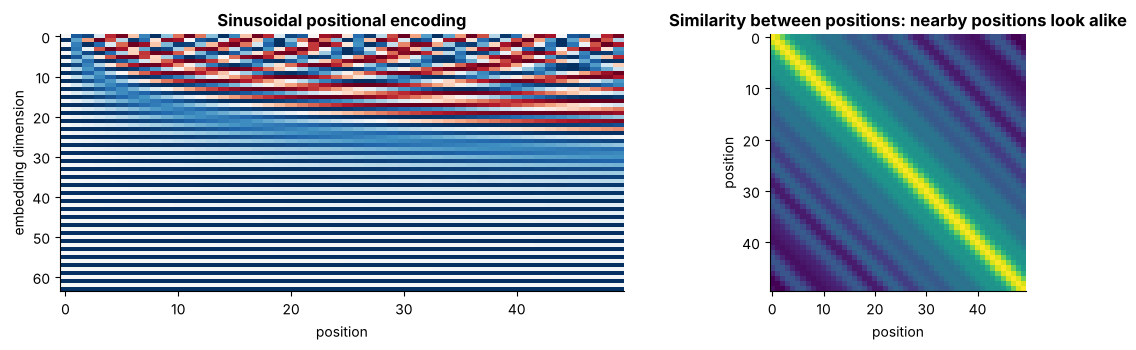

In [6]:
def sinusoidal_pe(n_pos, d):
    pos = np.arange(n_pos)[:, None]; i = np.arange(0, d, 2)[None, :]
    angle = pos / 10000 ** (i / d)
    pe = np.zeros((n_pos, d)); pe[:, 0::2], pe[:, 1::2] = np.sin(angle), np.cos(angle)
    return pe
pe = sinusoidal_pe(50, 64)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].imshow(pe.T, cmap="RdBu", aspect="auto"); ax[0].set(xlabel="position", ylabel="embedding dimension", title="Sinusoidal positional encoding"); ax[0].grid(False)
sim = pe @ pe.T; ax[1].imshow(sim, cmap="viridis"); ax[1].set(title="Similarity between positions: nearby positions look alike", xlabel="position", ylabel="position"); ax[1].grid(False)
plt.tight_layout(); plt.show()

---
## 🏗 6. The Transformer encoder block

One block = **attention** (tokens talk to each other) followed by a **feed-forward network** (each token thinks on its own), each wrapped with a **residual connection** (`x + sublayer(x)`, giving gradients a highway: Lesson 08's ResNet idea) and **LayerNorm** (normalise each token's features; the sequence-friendly cousin of BatchNorm):

```
x ─▶ LayerNorm ─▶ MultiHeadSelfAttention ─▶ (+) ─▶ LayerNorm ─▶ FeedForward (d → 4d → d, GELU) ─▶ (+) ─▶ out
└──────────────────────────────────────────┘      └─────────────────────────────────────────────────┘
      residual                                                    residual
```
(This "pre-norm" arrangement trains more stably than the original post-norm.) Stack $N$ blocks and you have a Transformer encoder.

In [7]:
class EncoderBlock(nn.Module):
    def __init__(self, d, heads, d_ff, drop=0.0):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(d), MultiHeadSelfAttention(d, heads)
        self.ln2, self.ff = nn.LayerNorm(d), nn.Sequential(nn.Linear(d, d_ff), nn.GELU(), nn.Linear(d_ff, d))
        self.drop = nn.Dropout(drop)
    def forward(self, x, mask=None):
        x = x + self.drop(self.attn(self.ln1(x), mask))       # tokens communicate
        x = x + self.drop(self.ff(self.ln2(x)))               # tokens compute
        return x

block = EncoderBlock(d=64, heads=4, d_ff=256)
print("block parameters:", f"{dl.count_params(block):,}", "| formula 4d² + 2·d·d_ff + 9d + d_ff =", 4 * 64**2 + 2 * 64 * 256 + 9 * 64 + 256)
print("shape preserved:", tuple(block(torch.randn(2, 10, 64)).shape), " ← so blocks can be stacked indefinitely")

block parameters: 49,984 | formula 4d² + 2·d·d_ff + 9d + d_ff = 49984
shape preserved: (2, 10, 64)  ← so blocks can be stacked indefinitely


> 📝 **Note**: **Cost warning.** Attention compares every token with every token: memory and time grow as **O(T²)** in sequence length. 1,000 tokens → 1 million pairs per head per layer. That's why long-context research (sparse/linear/flash attention) is a huge field.

---
## 🎭 7. Masks and the three families

A **mask** controls who may attend to whom. For *generating* text left-to-right, token *t* must not peek at tokens after it: use a **causal (lower-triangular) mask**.

In [8]:
T = 5
causal = np.tril(np.ones((T, T), bool))
rng = np.random.default_rng(1); Z = rng.normal(size=(T, 8))
_, w_causal = attention(Z, Z, Z, mask=causal)
print("causal attention weights (row t only attends to tokens ≤ t):\n", w_causal.round(2))

causal attention weights (row t only attends to tokens ≤ t):
 [[1.   0.   0.   0.   0.  ]
 [0.32 0.68 0.   0.   0.  ]
 [0.17 0.18 0.66 0.   0.  ]
 [0.   0.   0.01 0.99 0.  ]
 [0.04 0.08 0.04 0.01 0.83]]


| Family | Attention | Trained to… | Examples | Typical use |
|:--|:--|:--|:--|:--|
| **Encoder-only** | Bidirectional (no mask) | Fill in masked tokens | BERT, **ViT** | Classification, search, understanding |
| **Decoder-only** | **Causal** mask | Predict the next token | **GPT**, Llama, Claude-style LLMs | Text generation, chat, code |
| **Encoder–decoder** | Encoder bidirectional; decoder causal + *cross-attention* to the encoder | Map one sequence to another | T5, original Transformer, Whisper | Translation, summarisation, speech |

Large language models are *decoder-only Transformers trained at enormous scale*: the architecture you're about to build, with more blocks, more heads, more data.

---
## 🖼 8. A mini Vision Transformer (ViT) on MNIST

Can attention read digits? **ViT** (Dosovitskiy et al., 2020) turns an image into a *sequence of patches*:

1. Cut the 28×28 image into **16 patches of 7×7** (a 4×4 grid) → flatten each to 49 numbers.
2. **Linear-embed** each patch to a $d$-dim token; prepend a learnable **[CLS] token** (a "summary" slot).
3. Add **learned position embeddings**.
4. Run through encoder blocks.
5. Classify from the [CLS] token's final vector.

parameters: 19,658 | tokens per image: 17 | patches shape: (2, 16, 49)


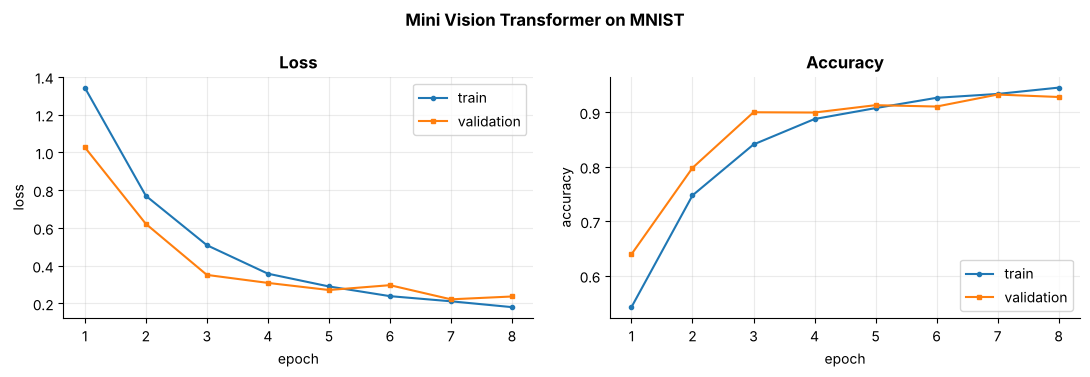

final validation accuracy: 92.80%   (10s)


In [9]:
def patchify(x, p):
    """(B, C, H, W) → (B, num_patches, C·p·p)."""
    B, C, H, W = x.shape
    return x.reshape(B, C, H // p, p, W // p, p).permute(0, 2, 4, 1, 3, 5).reshape(B, (H // p) * (W // p), C * p * p)

class MiniViT(nn.Module):
    def __init__(self, patch=7, d=32, heads=4, depth=2, d_ff=64, n_classes=10):
        super().__init__()
        n = (28 // patch) ** 2
        self.patch = patch
        self.embed = nn.Linear(patch * patch, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.randn(1, n + 1, d) * 0.02)
        self.blocks = nn.ModuleList([EncoderBlock(d, heads, d_ff) for _ in range(depth)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, n_classes)
    def forward(self, x):                                           # x: (B, 1, 28, 28)
        tokens = self.embed(patchify(x, self.patch))                # (B, 16, d)
        tokens = torch.cat([self.cls.expand(len(x), -1, -1), tokens], 1) + self.pos     # (B, 17, d)
        for blk in self.blocks:
            tokens = blk(tokens)
        return self.head(self.ln(tokens[:, 0]))                     # classify from [CLS]

x_tr, y_tr, x_te, y_te = dl.load_mnist(n_train=10000, n_test=2000)
mu, sd = x_tr.mean(), x_tr.std()
to_t = lambda a: torch.tensor((a - mu) / sd, dtype=torch.float32)[:, None]
Xtr, Xte = to_t(x_tr), to_t(x_te)
train_dl = DataLoader(TensorDataset(Xtr, torch.tensor(y_tr)), batch_size=64, shuffle=True)
test_dl = DataLoader(TensorDataset(Xte, torch.tensor(y_te)), batch_size=500)

dl.set_seed(0)
vit = MiniViT()
print("parameters:", f"{dl.count_params(vit):,}", "| tokens per image:", 16 + 1, "| patches shape:", tuple(patchify(Xtr[:2], 7).shape))
hist = dl.fit(vit, train_dl, test_dl, nn.CrossEntropyLoss(), torch.optim.AdamW(vit.parameters(), lr=2e-3, weight_decay=1e-2), epochs=8, device=cpu, verbose=False)
dl.plot_history(hist, "Mini Vision Transformer on MNIST")
print(f"final validation accuracy: {hist['val_acc'][-1]:.2%}   ({hist['seconds']:.0f}s)")

> 💡 **Big idea**: A model with **no convolutions at all** reads digits well. It has no built-in notion of 'local' or 'shift-tolerant' (it *learns* spatial relationships from data through attention. That flexibility has a price: ViTs usually need **more data (or pre-training)** than CNNs, because a CNN gets locality for free. Compare with Lesson 08's CNN) same data, and the CNN typically wins at this small scale. *Inductive bias matters most when data is scarce.*

---
## 👁 9. Looking at attention

The [CLS] token's attention over the 16 patches shows *which parts of the digit it reads* when summarising. (Averaged over heads, last block.)

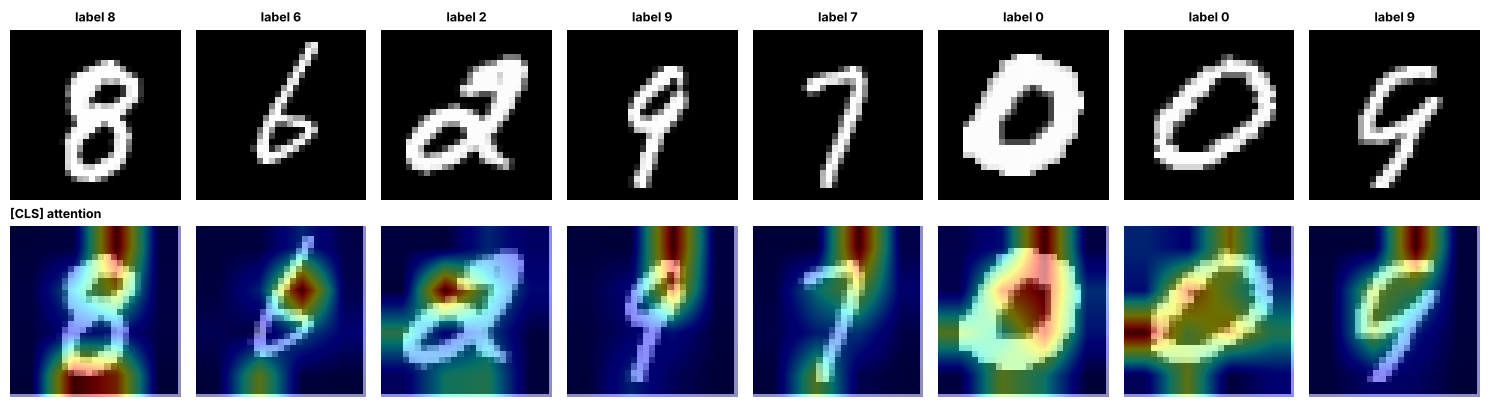

In [10]:
vit.eval()
idx = [0, 1, 2, 3, 4, 5, 6, 7]
with torch.no_grad():
    vit(Xte[idx])
attn = vit.blocks[-1].attn.last_attn                          # (B, heads, 17, 17)
cls_to_patches = attn[:, :, 0, 1:].mean(1).reshape(-1, 4, 4).numpy()       # (B, 4, 4)
fig, axes = plt.subplots(2, len(idx), figsize=(15, 4.2))
for k, i in enumerate(idx):
    axes[0, k].imshow(x_te[i], cmap="gray"); axes[0, k].set_title(f"label {y_te[i]}", fontsize=9)
    axes[1, k].imshow(x_te[i], cmap="gray"); axes[1, k].imshow(cls_to_patches[k], cmap="jet", alpha=.45, extent=(0, 28, 28, 0), interpolation="bilinear")
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[1, 0].set_title("[CLS] attention", fontsize=9, loc="left"); plt.tight_layout(); plt.show()

> 📝 **Note**: Attention maps are a *window*, not a full explanation: high attention doesn't guarantee a patch caused the prediction. Notice the model often attends strongly to **empty** patches too (e.g. the blank area above a digit): *where there is no ink* is informative as well. A handy diagnostic and a great teaching picture, not a proof.

---
## ⚖️ 10. Trade-offs: which architecture when?

| | **CNN** | **RNN / LSTM / GRU** | **Transformer** |
|:--|:--|:--|:--|
| Built-in assumption | Local, shift-invariant patterns | Sequential order, short-ish memory | Almost none: learns relations from data |
| Parallel over sequence? | ✅ | ❌ (sequential) | ✅ |
| Long-range dependencies | Need depth/dilation | Weak (even LSTM) | ✅ direct, any distance |
| Cost in sequence length | Linear | Linear | **Quadratic** |
| Data hunger | Low–medium | Low–medium | **High** (or pre-trained) |
| Best for | Images (small data), audio spectrograms | Small time-series, streaming, tiny devices | Text, large-scale vision, anything with lots of data/pre-training |

**For this course's projects:** CNNs for the leaf photos (small data, images); gated RNNs or even ridge for our few-hundred-window price series; Transformers when you have lots of data or can fine-tune a pre-trained model. *Use the simplest architecture that works.*

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 13.1: Scaled dot-product attention with a mask  &nbsp; `⭐⭐`

Implement `attention(Q, K, V, mask=None)` returning `(output, weights)`. Scores = `Q Kᵀ / √d_k`; where `mask` is `False` the score must become a huge negative number (e.g. −1e9) *before* the softmax; softmax over the last axis (keys).

<details><summary>💡 Hint 1</summary>

`scores = Q @ K.T / np.sqrt(K.shape[-1])`.

</details>

<details><summary>💡 Hint 2</summary>

`scores = np.where(mask, scores, -1e9)` if a mask is given.

</details>

<details><summary>💡 Hint 3</summary>

Stable softmax: subtract the row max, exponentiate, divide by the row sum; `weights @ V` is the output.

</details>


In [ ]:
def attention(Q, K, V, mask=None):
    pass   # return output, weights

In [ ]:
# ▶ self-check (run after you've written your answer)
X = np.array([[1., 0.], [0., 1.], [1., 1.]])
r = attention(X, X, X)
dl.check("worked example, row 1 weights (.40, .20, .40)", r is not None and np.allclose(r[1][0], [.40, .20, .40], atol=.01))
dl.check("worked example, row 1 output (.80, .60)", r is not None and np.allclose(r[0][0], [.80, .60], atol=.01))
dl.check("rows of weights sum to 1", r is not None and np.allclose(r[1].sum(1), 1))
rc = attention(X, X, X, mask=np.tril(np.ones((3, 3), bool)))
dl.check("causal mask: token 0 attends only to itself", rc is not None and np.allclose(rc[1][0], [1, 0, 0], atol=1e-6))
dl.check("causal mask: token 1 ignores token 2", rc is not None and rc[1][1, 2] < 1e-6)

---
### 🧩 Problem 13.2: Sinusoidal positional encoding  &nbsp; `⭐⭐`

Write `sinusoidal_pe(n_pos, d)` (d even) returning an `(n_pos, d)` array with `PE[pos, 2i] = sin(pos / 10000^(2i/d))` and `PE[pos, 2i+1] = cos(...)`.

<details><summary>💡 Hint 1</summary>

`pos = np.arange(n_pos)[:, None]`, `i2 = np.arange(0, d, 2)[None, :]` (these are the even indices 2i).

</details>

<details><summary>💡 Hint 2</summary>

`angle = pos / 10000 ** (i2 / d)`.

</details>

<details><summary>💡 Hint 3</summary>

Fill even columns with `sin(angle)` and odd columns with `cos(angle)`.

</details>


In [ ]:
def sinusoidal_pe(n_pos, d):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
pe = sinusoidal_pe(10, 8)
dl.check("shape (10, 8)", pe is not None and pe.shape == (10, 8))
dl.check("position 0 is [0,1,0,1,...]", pe is not None and np.allclose(pe[0], [0, 1] * 4))
dl.check("PE[1,0] = sin(1) and PE[1,1] = cos(1)", pe is not None and np.isclose(pe[1, 0], np.sin(1)) and np.isclose(pe[1, 1], np.cos(1)))
dl.check("last pair uses a much slower wave: PE[1,6] = sin(1/10000^(6/8))", pe is not None and np.isclose(pe[1, 6], np.sin(1 / 10000 ** 0.75)))

---
### 🧩 Problem 13.3: Count a Transformer block  &nbsp; `⭐⭐`

Write `block_params(d, d_ff)`: the number of parameters in one encoder block: attention (`Q,K,V` and output projections, each with bias), the two feed-forward linear layers (with biases), and two LayerNorms (weight + bias each). Verify against PyTorch's `nn.TransformerEncoderLayer`.

<details><summary>💡 Hint 1</summary>

Attention: `4·d·d + 4·d`.

</details>

<details><summary>💡 Hint 2</summary>

Feed-forward: `d·d_ff + d_ff` and `d_ff·d + d`.

</details>

<details><summary>💡 Hint 3</summary>

Each LayerNorm has `2d` parameters; there are two.

</details>


In [ ]:
def block_params(d, d_ff):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
ref = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=256, batch_first=True, norm_first=True)
dl.check("matches nn.TransformerEncoderLayer (d=64, d_ff=256)", block_params(64, 256) == dl.count_params(ref))
dl.check("also for d=32, d_ff=64", block_params(32, 64) == dl.count_params(nn.TransformerEncoderLayer(32, 4, 64, batch_first=True)))

---
### 🧩 Problem 13.4: Split and merge heads  &nbsp; `⭐⭐`

Write `split_heads(x, h)` turning `(B, T, d)` into `(B, h, T, d/h)`, and `merge_heads(x)` as its exact inverse. These two reshapes are the core of multi-head attention.

<details><summary>💡 Hint 1</summary>

`x.reshape(B, T, h, d // h)` then `.transpose(1, 2)` to move heads before time.

</details>

<details><summary>💡 Hint 2</summary>

Inverse: `.transpose(1, 2).reshape(B, T, h * dk)`.

</details>


In [ ]:
def split_heads(x, h):
    pass

def merge_heads(x):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
x = torch.randn(2, 5, 12)
s = split_heads(x, 3)
dl.check("split shape (2, 3, 5, 4)", s is not None and tuple(s.shape) == (2, 3, 5, 4))
dl.check("head 0 holds the first 4 features of every token", s is not None and torch.equal(s[:, 0], x[:, :, :4]))
dl.check("merge(split(x)) == x", s is not None and torch.equal(merge_heads(s), x))

---
### 🧩 Problem 13.5: Patchify an image (challenge)  &nbsp; `⭐⭐⭐`

Write `patchify(x, p)`: `(B, C, H, W) → (B, (H/p)·(W/p), C·p·p)` where patches are taken in **row-major** order and each patch is flattened. Use only reshape/permute (no loops).

<details><summary>💡 Hint 1</summary>

Reshape to `(B, C, H//p, p, W//p, p)`: this exposes the grid of patches and the pixels inside each patch.

</details>

<details><summary>💡 Hint 2</summary>

Permute to `(B, H//p, W//p, C, p, p)`: patch-grid axes first, patch contents last.

</details>

<details><summary>💡 Hint 3</summary>

Finally reshape to `(B, num_patches, C·p·p)`.

</details>


In [ ]:
def patchify(x, p):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
x = torch.arange(16, dtype=torch.float32).reshape(1, 1, 4, 4)          # [[0 1 2 3],[4 5 6 7],[8 9 10 11],[12 13 14 15]]
r = patchify(x, 2)
dl.check("shape (1, 4, 4)", r is not None and tuple(r.shape) == (1, 4, 4))
dl.check("first patch = top-left 2×2 = [0, 1, 4, 5]", r is not None and r[0, 0].tolist() == [0, 1, 4, 5])
dl.check("second patch = top-right = [2, 3, 6, 7]", r is not None and r[0, 1].tolist() == [2, 3, 6, 7])
dl.check("last patch = bottom-right = [10, 11, 14, 15]", r is not None and r[0, 3].tolist() == [10, 11, 14, 15])
dl.check("works for 28×28 / 7 → 16 patches of 49", patchify(torch.randn(3, 1, 28, 28), 7).shape == (3, 16, 49))

---
## 🏁 Key takeaways
- ✅ **Attention** = each token takes a **weighted average of all tokens' values**, with weights from query–key similarity: `softmax(QKᵀ/√d)V`.
- ✅ Dividing by **√d** keeps the softmax out of saturation; **masks** (e.g. causal) control who may attend to whom.
- ✅ **Multi-head** attention runs several attention patterns in parallel in lower-dimensional subspaces.
- ✅ Attention is **order-blind**, so we add **positional information** (sinusoidal or learned).
- ✅ An **encoder block** = attention + feed-forward, each with **residual + LayerNorm**; stack blocks to go deep. Cost grows **O(T²)**.
- ✅ **Encoder-only** (BERT, ViT), **decoder-only** (GPT/LLMs), **encoder–decoder** (T5, translation). A **ViT** treats image patches as tokens.
- ✅ Transformers have little built-in bias → they shine with **lots of data or pre-training**; CNNs/RNNs/ridge often win on small data.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** In attention, what do the queries, keys and values represent?

<details><summary>Answer</summary>

Queries: what each token is looking for. Keys: what each token offers for matching. Values: the information each token contributes. Output = weights(query·key) applied to values.

</details>

**Q2.** Why does a Transformer need positional encodings but a CNN or RNN doesn't?

<details><summary>Answer</summary>

Convolutions use fixed neighbour positions and RNNs process tokens in order, so order is built in. Attention is permutation-equivariant, without positional information the order is invisible.

</details>

**Q3.** What does a causal mask do and why is it used for text generation?

<details><summary>Answer</summary>

It blocks attention to later positions so token t can only use tokens ≤ t. During training this mimics generation, where future tokens don't exist yet.

</details>

**Q4.** You double the sequence length. Roughly how does attention's cost change?

<details><summary>Answer</summary>

Quadruples (O(T²): every token attends to every other).

</details>

**Q5.** Why did our mini-ViT likely underperform the CNN on 10,000 digits?

<details><summary>Answer</summary>

A CNN has locality and weight sharing built in; the ViT must learn spatial structure from data, which needs more examples (or pre-training).

</details>

---
## 📚 Go deeper (optional)
- Vaswani et al. (2017): *Attention Is All You Need*
- Jay Alammar: *The Illustrated Transformer* (jalammar.github.io)
- Andrej Karpathy: *Let's build GPT: from scratch, in code, spelled out* (YouTube) and *nanoGPT*
- Dosovitskiy et al. (2020): *An Image is Worth 16×16 Words* (ViT)
- Harvard NLP: *The Annotated Transformer*

---
⬅️ Previous: [12 · Project 4 · LSTM Maize Price Forecasting](12_project4_price_forecasting.ipynb) &nbsp;|&nbsp; Next: [14 · Deep Learning Optimisation & Regularisation](14_optimization_regularization.ipynb) ➡️